# Paper PCA figures
Three datasets selected by largest retrospective family G-mean gain over the strongest of SMOTE, Borderline-SMOTE, ROS and ADASYN, among 40 complete datasets. Scores average both classifiers and all folds/seeds. These are selected illustrations, not an unbiased evaluation.

Resampling uses the actual shared implementation in full preprocessed feature space. Training fold 1 / seed 42 is fixed before viewing plots; each method uses its saved SVM inner-validation ratio. PCA and preprocessing fit original training data only; no test data enters the visualization. All panels share axes. CASB-edited removed points are shown as purple reference crosses, not retained samples. CASB-ROS adds duplicate observations, represented by green rings without artificial jitter. Abalone uses the benchmark one-hot encoding; interpolated dummy values may be fractional.

Run from this directory or the project root. Results and provenance stay in this notebook; progress.md is unchanged.

,best_variant,family_gmean,best_baseline_gmean,gain_pp
dataset,,,,
abalone19,casb_edited,0.555709,0.512824,4.288535
yeast-1-2-8-9_vs_7,casb_edited,0.663831,0.622890,4.094039
haberman,casb_edited,0.632319,0.596793,3.552631


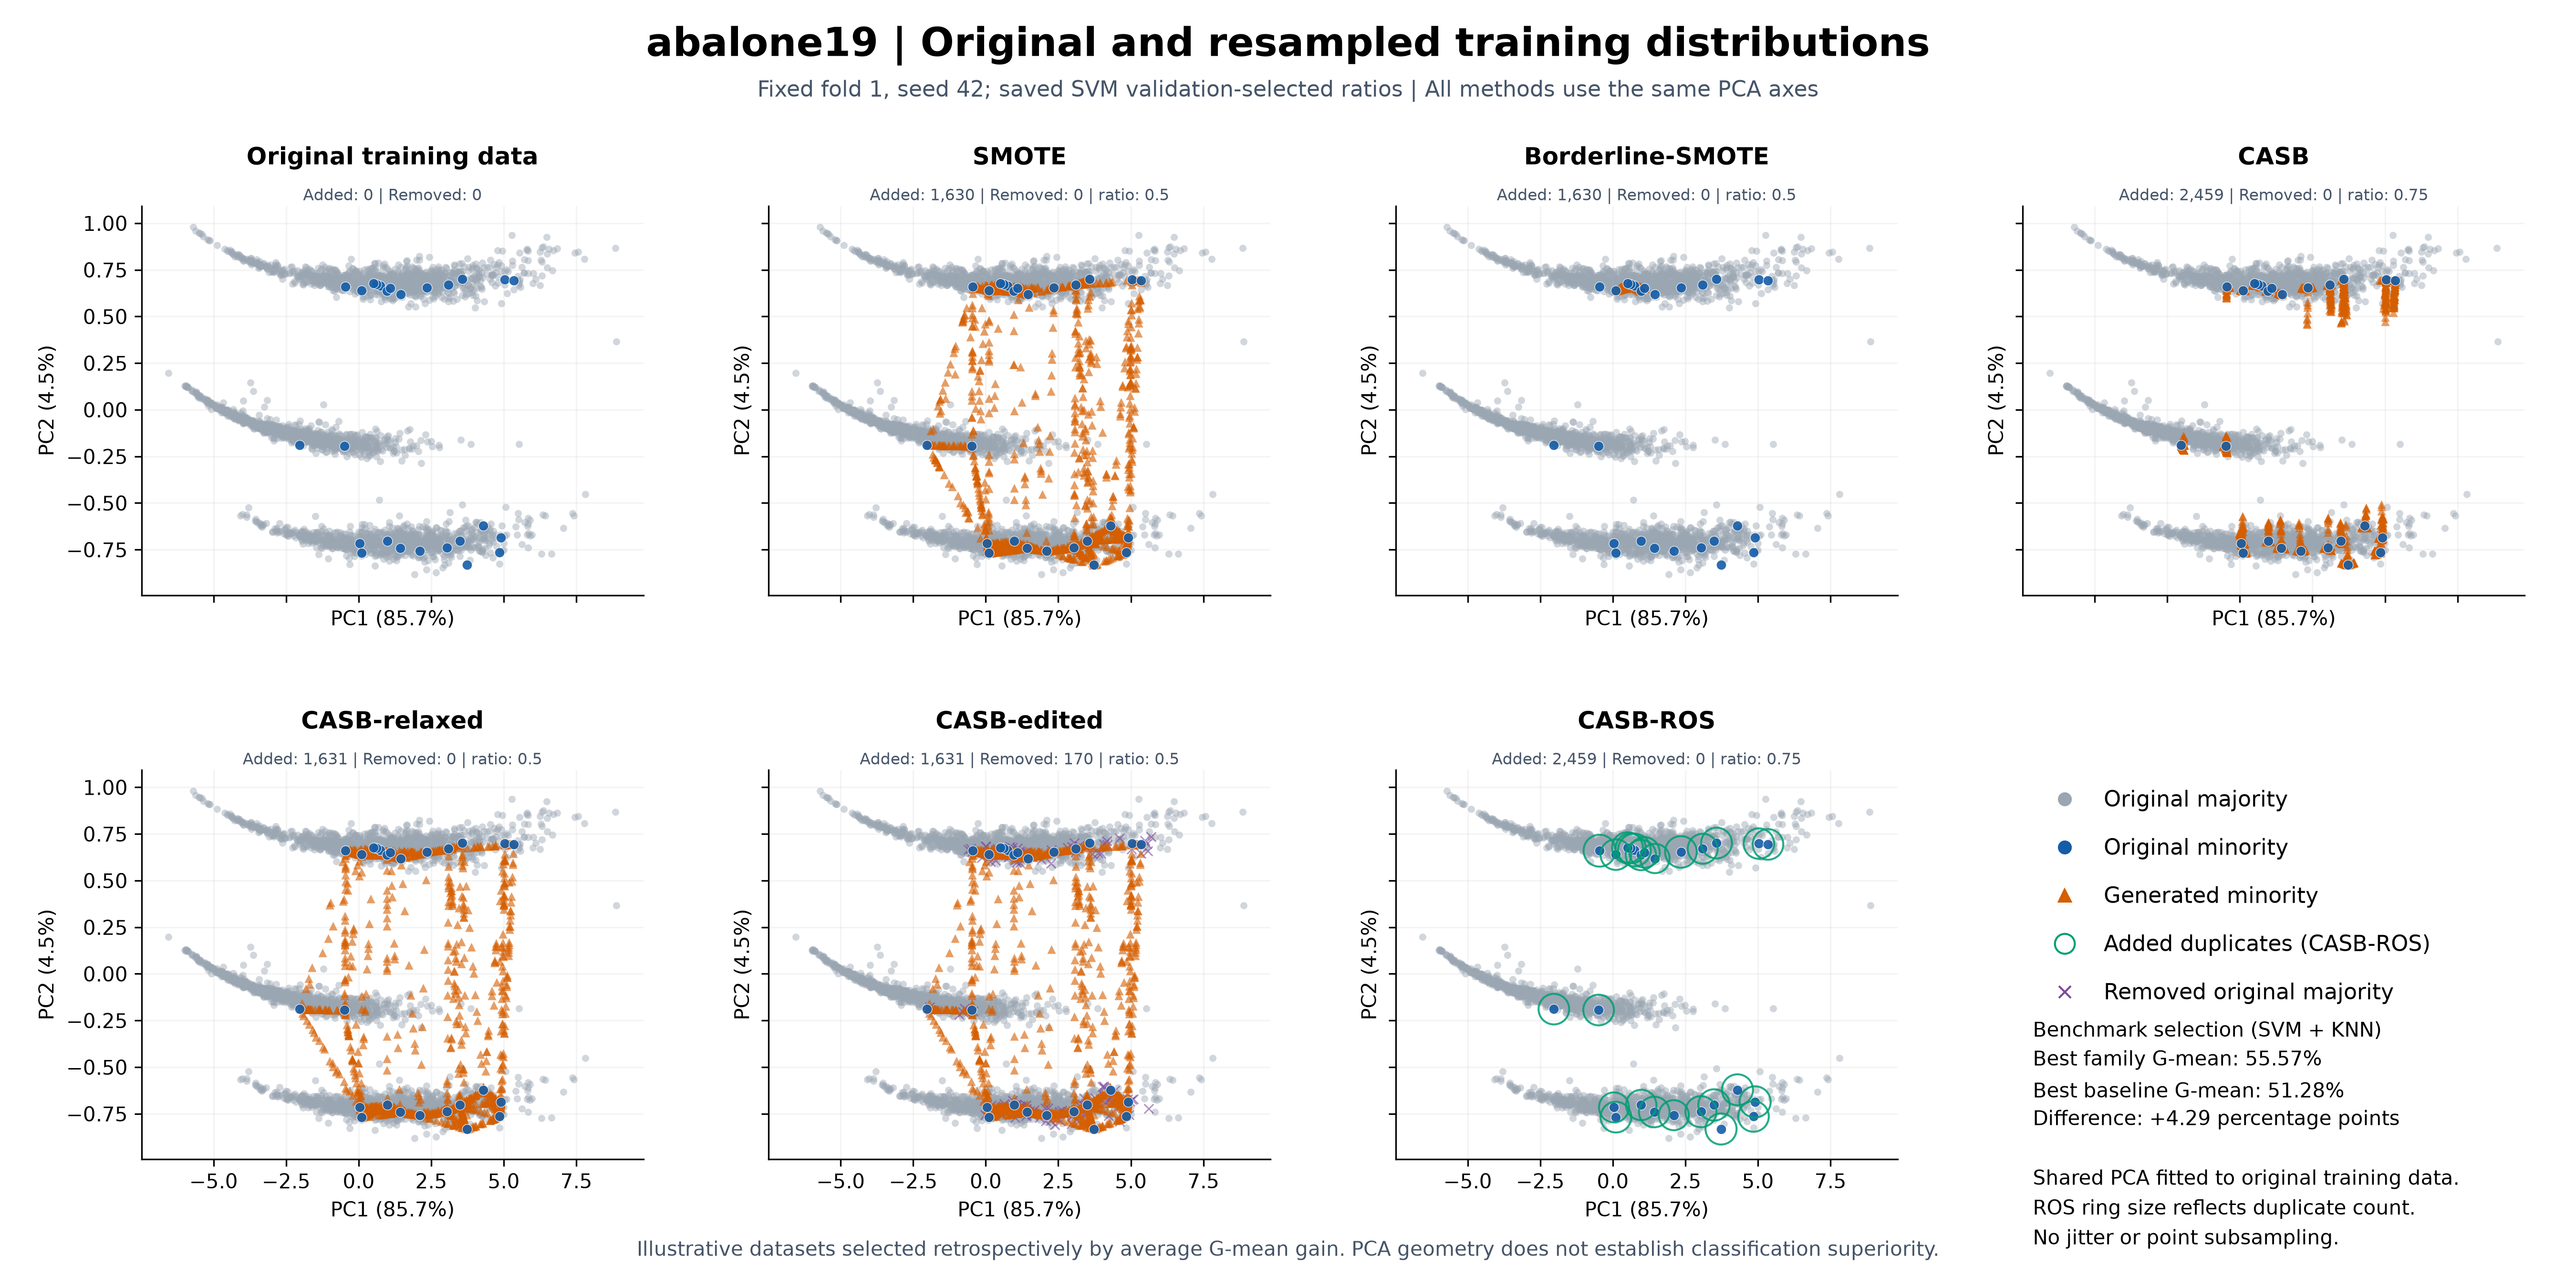

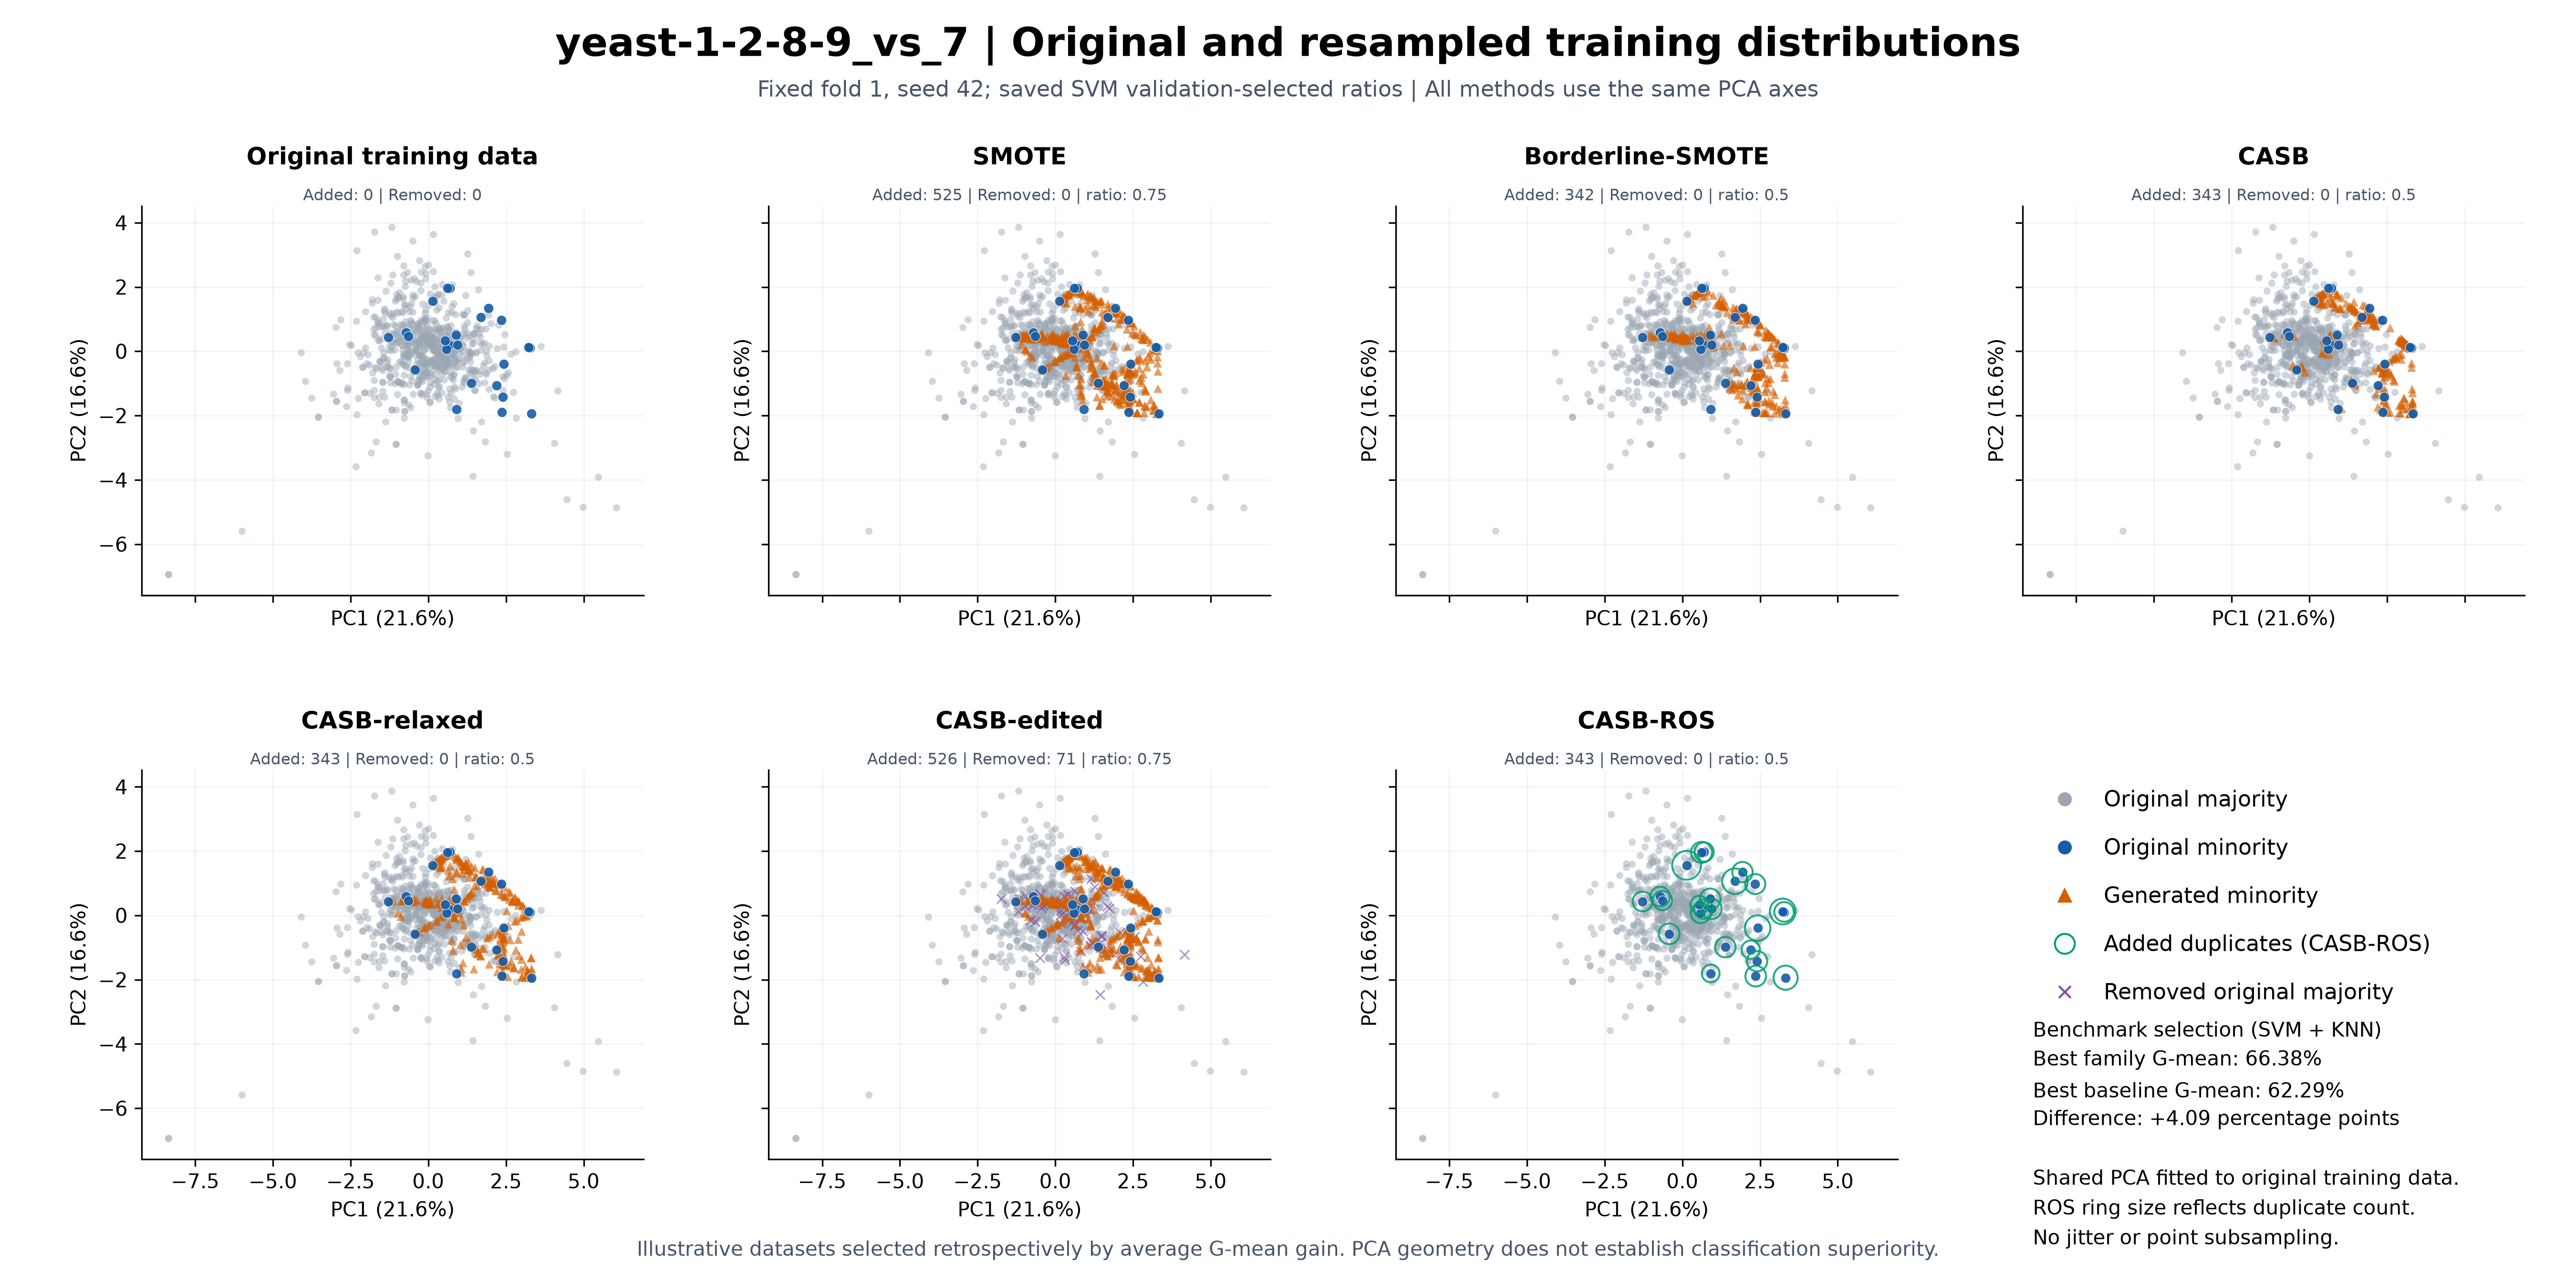

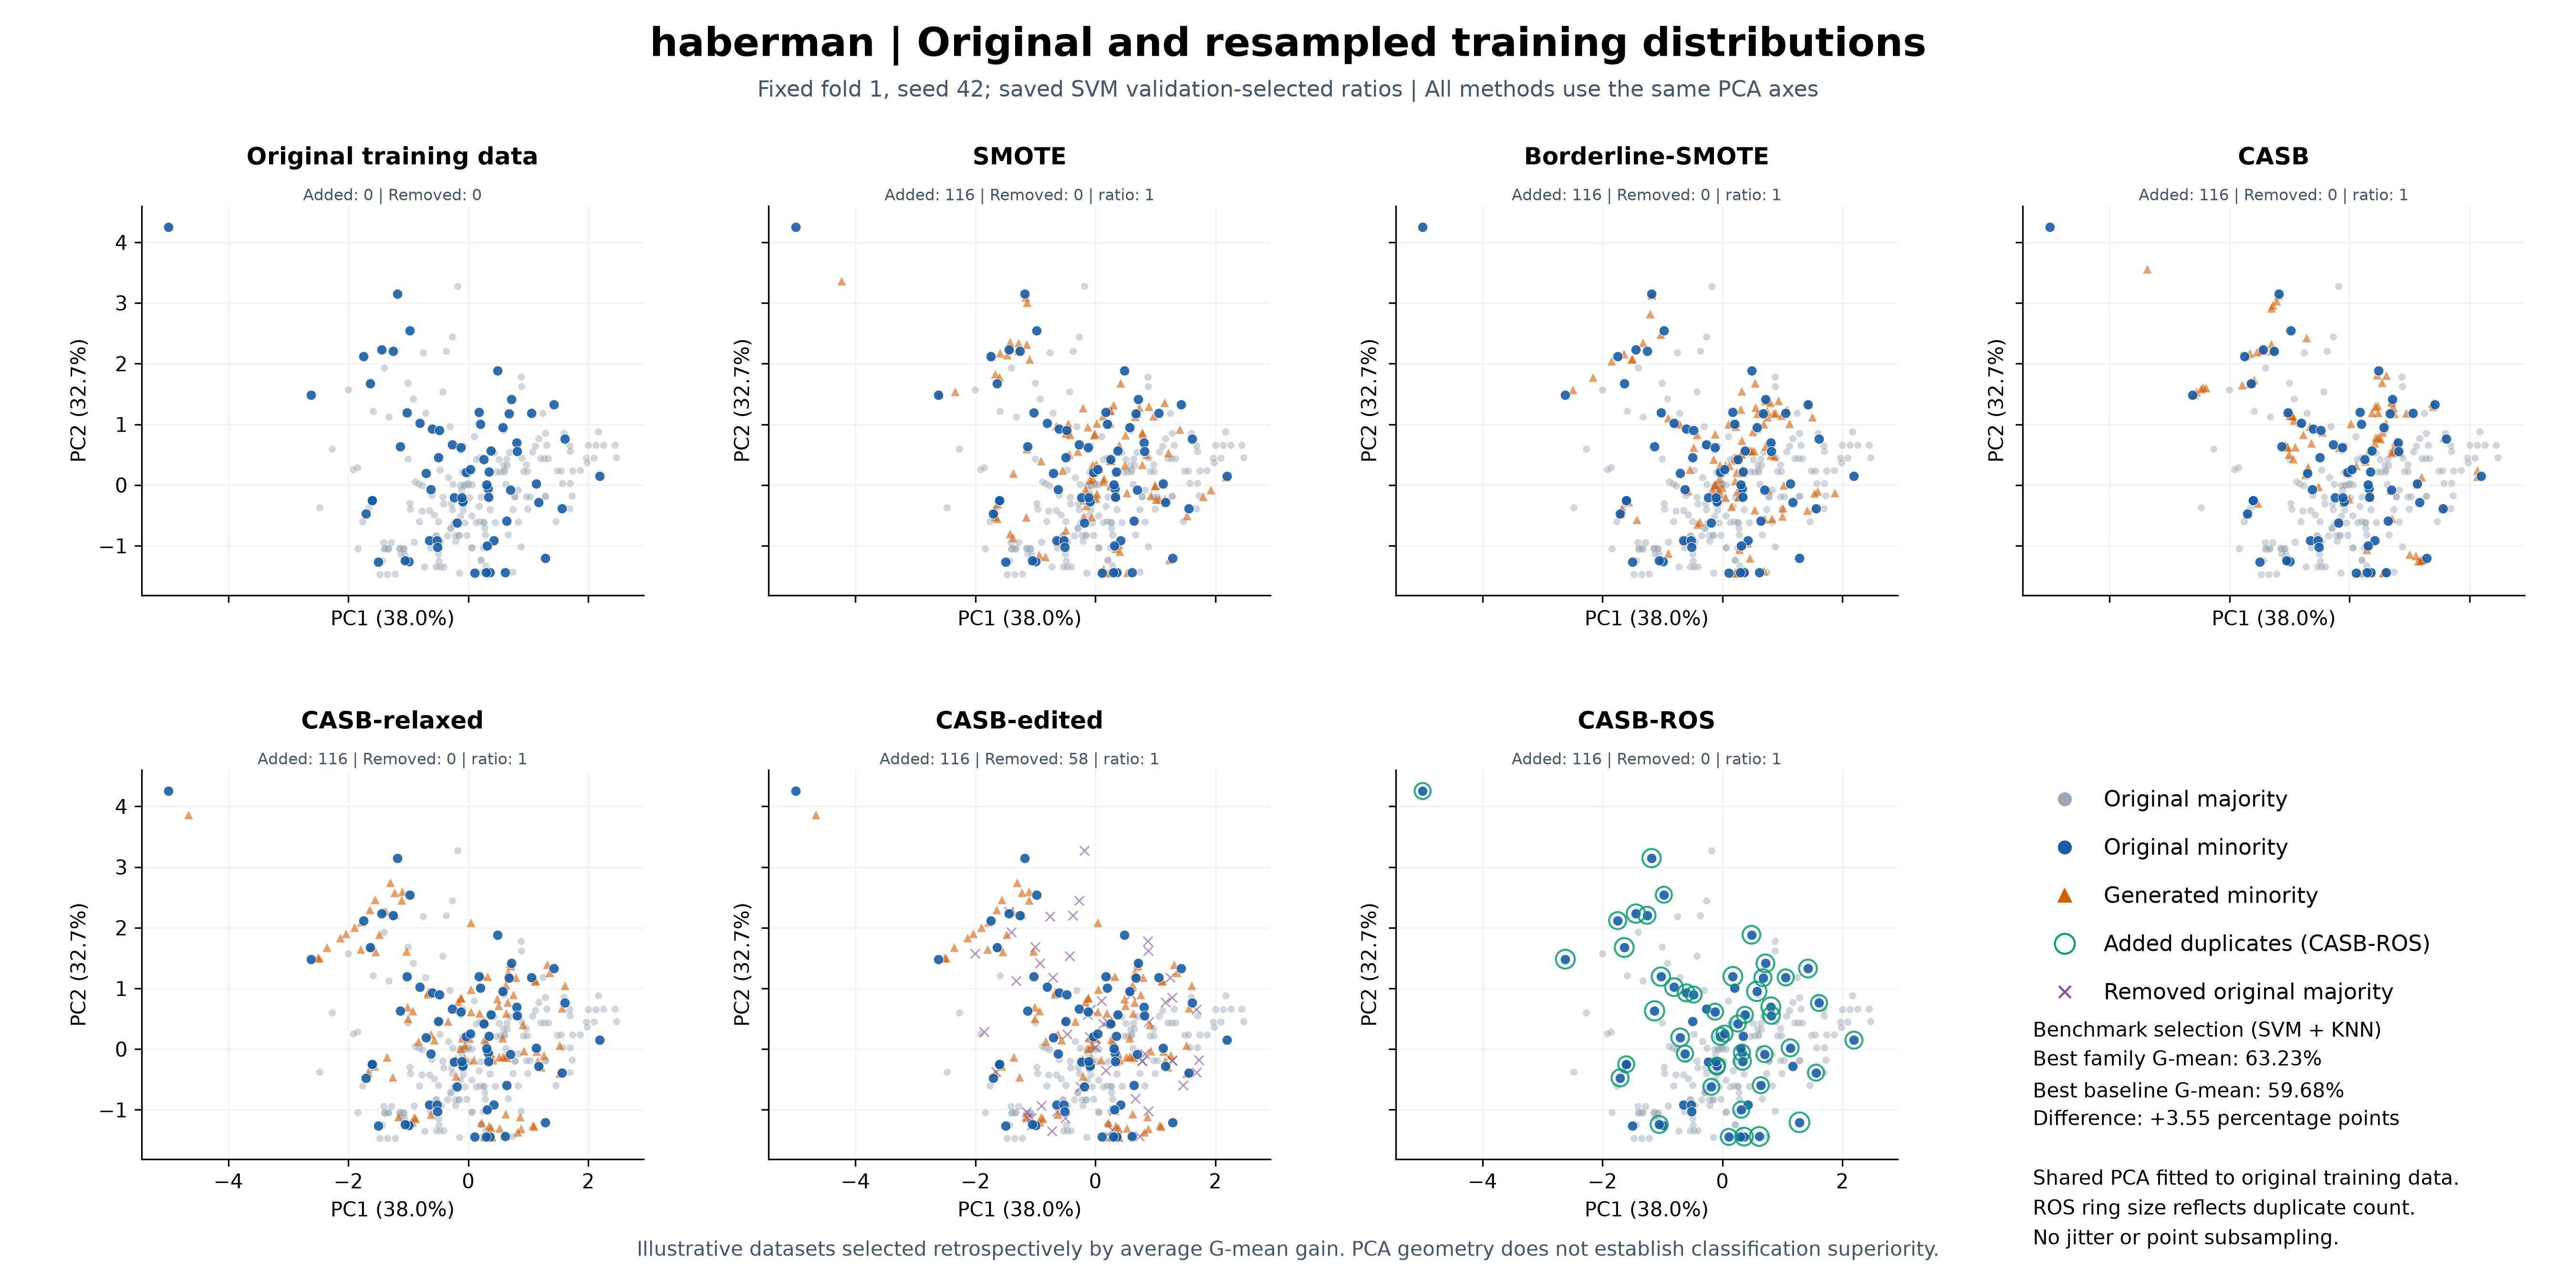

,dataset,method,ratio,original_retained,added,removed,train_sha256,pc1,pc2
0,abalone19,original,0.50,3339,0,0,b7f9f62f38329ee29d8997cad47243fd12551222039dc9...,0.856533,0.044563
1,abalone19,smote,0.50,3339,1630,0,b7f9f62f38329ee29d8997cad47243fd12551222039dc9...,0.856533,0.044563
2,abalone19,bsmote,0.50,3339,1630,0,b7f9f62f38329ee29d8997cad47243fd12551222039dc9...,0.856533,0.044563
3,abalone19,casb,0.75,3339,2459,0,b7f9f62f38329ee29d8997cad47243fd12551222039dc9...,0.856533,0.044563
4,abalone19,casb_relaxed,0.50,3339,1631,0,b7f9f62f38329ee29d8997cad47243fd12551222039dc9...,0.856533,0.044563
5,abalone19,casb_edited,0.50,3169,1631,170,b7f9f62f38329ee29d8997cad47243fd12551222039dc9...,0.856533,0.044563
6,abalone19,casb_ros,0.75,3339,2459,0,b7f9f62f38329ee29d8997cad47243fd12551222039dc9...,0.856533,0.044563
7,yeast-1-2-8-9_vs_7,original,0.50,757,0,0,217e0ff011dc0fb6db4d8e904593aab7de0c75ed14f411...,0.215653,0.166149
8,yeast-1-2-8-9_vs_7,smote,0.75,757,525,0,217e0ff011dc0fb6db4d8e904593aab7de0c75ed14f411...,0.215653,0.166149
9,yeast-1-2-8-9_vs_7,bsmote,0.50,757,342,0,217e0ff011dc0fb6db4d8e904593aab7de0c75ed14f411...,0.215653,0.166149


Saved three PNGs and three PDFs in D:\SEM_5\ML_PROJECT\paper plot


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'binary_oversampling.py').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from binary_oversampling import read_data, sampler, binary_labels
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
OUT=ROOT/'paper plot'
methods=['original','smote','bsmote','casb','casb_relaxed','casb_edited','casb_ros']
names={'original':'Original training data','smote':'SMOTE','bsmote':'Borderline-SMOTE','casb':'CASB','casb_relaxed':'CASB-relaxed','casb_edited':'CASB-edited','casb_ros':'CASB-ROS'}
family=['casb','casb_relaxed','casb_edited','casb_ros'];baselines=['smote','bsmote','ros','adasyn']
rows=[];metadata={}
for path in sorted(ROOT.glob('[0-9][0-9]_*_CASB.ipynb')):
    nb=json.loads(path.read_text(encoding='utf8'));meta=nb['metadata']['current_comparison']
    rows.extend(meta['records']);metadata[meta['records'][0]['dataset']]=meta
frame=pd.DataFrame(rows);bad=set(frame.loc[frame.error.notna(),'dataset'])
means=frame[~frame.dataset.isin(bad)].groupby(['dataset','method']).gmean.mean().unstack()
ranking=pd.DataFrame({'best_variant':means[family].idxmax(axis=1),'family_gmean':means[family].max(axis=1),'best_baseline_gmean':means[baselines].max(axis=1)})
ranking['gain_pp']=100*(ranking.family_gmean-ranking.best_baseline_gmean)
ranking=ranking.sort_values('gain_pp',ascending=False)
selected=ranking.head(3)
display(selected)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':12,'axes.labelsize':10,'pdf.fonttype':42,'ps.fonttype':42})
provenance=[]
for dataset,score in selected.iterrows():
    train=ROOT/'output'/'All'/dataset/f'{dataset}-5-1tra.dat'
    if not train.exists():train=ROOT/'All'/dataset/f'{dataset}-5-1tra.dat'
    digest=hashlib.sha256(train.read_bytes()).hexdigest()
    assert digest in metadata[dataset]['input_sha256'].values()
    X,y=read_data(train,allow_nominal=True)
    minority_label,_,_=binary_labels(y)
    y=(y==minority_label).astype(int)
    numeric_prep=make_pipeline(SimpleImputer(strategy='median',keep_empty_features=True),StandardScaler())
    if X.dtype==object:
        categorical=[i for i in range(X.shape[1]) if any(isinstance(v,str) for v in X[:,i])]
        numeric=[i for i in range(X.shape[1]) if i not in categorical]
        prep=ColumnTransformer([('numeric',numeric_prep,numeric),('categorical',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore',sparse_output=False)),categorical)],sparse_threshold=0)
    else:prep=numeric_prep
    Z=prep.fit_transform(X);minority,majority,_=binary_labels(y)
    pca=PCA(n_components=2,svd_solver='full').fit(Z);original=pca.transform(Z)
    panels=[]
    for method in methods:
        saved=frame[(frame.dataset==dataset)&(frame.method==method)&(frame.classifier=='svm')&(frame.seed==42)&(frame.fold==1)]
        assert len(saved)==1
        ratio=float(saved.iloc[0].ratio)
        s=sampler(method,y,42,ratio)
        if s is None:zr,yr=Z.copy(),y.copy()
        else:zr,yr=s.fit_resample(Z,y)
        removed=np.asarray(getattr(s,'removed_indices_',[]),int)
        keep=np.ones(len(y),bool);keep[removed[removed<len(y)]]=False
        n_original=int(keep.sum())
        if method=='casb_edited' and s is not None:
            generated=s.generator_.generated_
            # ENN returns class-grouped rows, so positional slicing is invalid.
            expected_z=np.vstack([Z[keep],generated])
            expected_y=np.concatenate([y[keep],np.repeat(minority,len(generated))])
            from collections import Counter
            assert Counter(map(tuple,np.column_stack([zr,yr])))==Counter(map(tuple,np.column_stack([expected_z,expected_y])))
        else:
            assert np.allclose(zr[:n_original],Z[keep])
            assert np.array_equal(yr[:n_original],y[keep])
            generated=zr[n_original:]
            assert np.all(yr[n_original:]==minority)
        panels.append((method,ratio,original[keep],y[keep],pca.transform(generated) if len(generated) else np.empty((0,2)),original[~keep]))
        provenance.append(dict(dataset=dataset,method=method,ratio=ratio,original_retained=n_original,added=len(generated),removed=int((~keep).sum()),train_sha256=digest,pc1=float(pca.explained_variance_ratio_[0]),pc2=float(pca.explained_variance_ratio_[1])))
    allpts=np.vstack([original]+[p[4] for p in panels if len(p[4])]);lo=allpts.min(axis=0);hi=allpts.max(axis=0);pad=np.maximum((hi-lo)*.06,.1)
    fig,axes=plt.subplots(2,4,figsize=(18,9),sharex=True,sharey=True)
    for ax,(method,ratio,orig,labels,generated,removed) in zip(axes.flat,panels):
        ax.scatter(orig[labels==majority,0],orig[labels==majority,1],s=13,c='#9AA6B2',alpha=.45,linewidths=0,rasterized=True)
        ax.scatter(orig[labels==minority,0],orig[labels==minority,1],s=25,c='#155DA8',alpha=.9,linewidths=.3,edgecolors='white',rasterized=True,zorder=3)
        if len(generated):
            if method=='casb_ros':
                unique,counts=np.unique(generated,axis=0,return_counts=True)
                ax.scatter(unique[:,0],unique[:,1],s=45+20*np.sqrt(counts),facecolors='none',edgecolors='#009E73',linewidths=1,alpha=.85,zorder=4,rasterized=True)
            else:ax.scatter(generated[:,0],generated[:,1],s=19,c='#D55E00',marker='^',alpha=.6,linewidths=0,rasterized=True,zorder=2)
        if len(removed):ax.scatter(removed[:,0],removed[:,1],s=22,c='#7D489B',marker='x',alpha=.6,linewidths=.7,rasterized=True)
        ax.set_title(names[method],fontweight='bold',pad=21)
        detail=f'Added: {len(generated):,} | Removed: {len(removed):,}'
        if method!='original':detail+=f' | ratio: {ratio:g}'
        ax.text(.5,1.015,detail,transform=ax.transAxes,ha='center',fontsize=8,color='#455468')
        ax.set_xlim(lo[0]-pad[0],hi[0]+pad[0]);ax.set_ylim(lo[1]-pad[1],hi[1]+pad[1]);ax.grid(alpha=.13)
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})');ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
    key=axes.flat[-1];key.axis('off')
    handles=[Line2D([],[],marker='o',ls='',color='#9AA6B2',label='Original majority'),Line2D([],[],marker='o',ls='',color='#155DA8',label='Original minority'),Line2D([],[],marker='^',ls='',color='#D55E00',label='Generated minority'),Line2D([],[],marker='o',ls='',markerfacecolor='none',color='#009E73',markersize=10,label='Added duplicates (CASB-ROS)'),Line2D([],[],marker='x',ls='',color='#7D489B',label='Removed original majority')]
    key.legend(handles=handles,loc='upper left',frameon=False,fontsize=11,labelspacing=1.2)
    key.text(.02,.37,f'Benchmark selection (SVM + KNN)\nBest family G-mean: {100*score.family_gmean:.2f}%\nBest baseline G-mean: {100*score.best_baseline_gmean:.2f}%\nDifference: +{score.gain_pp:.2f} percentage points\n\nShared PCA fitted to original training data.\nROS ring size reflects duplicate count.\nNo jitter or point subsampling.',transform=key.transAxes,va='top',fontsize=10,linespacing=1.5)
    fig.suptitle(f'{dataset} | Original and resampled training distributions',fontsize=20,fontweight='bold',y=.98)
    fig.text(.5,.925,'Fixed fold 1, seed 42; saved SVM validation-selected ratios | All methods use the same PCA axes',ha='center',fontsize=11,color='#455468')
    fig.text(.5,.025,'Illustrative datasets selected retrospectively by average G-mean gain. PCA geometry does not establish classification superiority.',ha='center',fontsize=10,color='#455468')
    fig.subplots_adjust(left=.055,right=.98,bottom=.1,top=.84,wspace=.25,hspace=.45)
    stem=OUT/f'{dataset}_PCA_comparison'
    fig.savefig(stem.with_suffix('.png'),dpi=300,facecolor='white')
    fig.savefig(stem.with_suffix('.pdf'),facecolor='white')
    plt.close(fig)
    display(Image(filename=str(stem.with_suffix('.png')),width=1200))
display(pd.DataFrame(provenance))
print('Saved three PNGs and three PDFs in',OUT)
